In [2]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [4]:
%pip install torch

  Using cached networkx-3.2.1-py3-none-any.whl.metadata (5.2 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.6/73.6 MB 44.0 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 44.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 536.2/536.2 kB 17.6 MB/s  0:00:00
Using cached networkx-3.2.1-py3-none-any.whl (1.6 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [torch]32m5/6 [torch]]x]
Note: you may need to restart the kernel to use updated packages.


In [5]:
import json
import zipfile
import random
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn

from pathlib import Path
from collections import defaultdict

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)
from sklearn.preprocessing import LabelEncoder
from torch.utils.data import DataLoader, TensorDataset

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_DIR = Path(".")
ZIP_PATH = DATA_DIR / "fox8_23_dataset.ndjson.zip"
MANIFEST_PATH = DATA_DIR / "fox8_account_manifest.csv"
SPLIT_PATH = DATA_DIR / "fox8_account_splits.csv"

OUTPUT_DIR = Path("e1_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Device:", DEVICE)
print("Dataset:", ZIP_PATH.exists())
print("Manifest:", MANIFEST_PATH.exists())
print("Splits:", SPLIT_PATH.exists())

Device: cpu
Dataset: True
Manifest: True
Splits: True


In [6]:
manifest = pd.read_csv(MANIFEST_PATH)
splits = pd.read_csv(SPLIT_PATH)

print("Manifest columns:", manifest.columns.tolist())
print("Split columns:", splits.columns.tolist())

print("\nManifest preview:")
display(manifest.head())

print("\nSplit preview:")
display(splits.head())

Manifest columns: ['user_id', 'label', 'datasets', 'record_count', 'total_tweet_records', 'unique_tweet_ids', 'tweets_without_id', 'source_lines', 'label_conflict', 'label_values']
Split columns: ['user_id', 'label', 'datasets', 'record_count', 'total_tweet_records', 'unique_tweet_ids', 'tweets_without_id', 'source_lines', 'label_conflict', 'label_values', 'split', 'dataset_name']

Manifest preview:


,user_id,label,datasets,record_count,total_tweet_records,unique_tweet_ids,tweets_without_id,source_lines,label_conflict,label_values
0,1000410554064830470,human,midterm-2018,1,200,200,0,696,False,human
1,1009265903022768128,human,midterm-2018,1,200,200,0,758,False,human
2,101011196,human,gilani-17,1,200,200,0,547,False,human
3,1012403980239065088,human,midterm-2018,1,199,199,0,769,False,human
4,1013658288964161536,human,midterm-2018,1,91,91,0,610,False,human



Split preview:


,user_id,label,datasets,record_count,total_tweet_records,unique_tweet_ids,tweets_without_id,source_lines,label_conflict,label_values,split,dataset_name
0,616266129,bot,fox8,1,130,130,0,1151,False,bot,train,Fox8
1,2835653131,human,gilani-17,1,200,200,0,566,False,human,train,Fox8
2,184022143,human,varol-icwsm,1,199,199,0,877,False,human,train,Fox8
3,3104008712,bot,fox8,1,198,198,0,2080,False,bot,train,Fox8
4,729303740,bot,fox8,1,118,118,0,2120,False,bot,train,Fox8


In [7]:
def find_column(df, candidates, description):
    for col in candidates:
        if col in df.columns:
            return col
    raise ValueError(
        f"Không tìm thấy cột {description}. "
        f"Các cột hiện có: {df.columns.tolist()}"
    )

manifest_uid = find_column(
    manifest, ["user_id", "account_id", "id"], "user_id trong manifest"
)
manifest_label = find_column(
    manifest, ["label", "class", "target"], "label trong manifest"
)
split_uid = find_column(
    splits, ["user_id", "account_id", "id"], "user_id trong split"
)
split_name = find_column(
    splits, ["split", "set", "subset"], "split"
)

# Label ưu tiên lấy từ manifest
accounts = manifest[[manifest_uid, manifest_label]].copy()
accounts.columns = ["user_id", "label"]

split_table = splits[[split_uid, split_name]].copy()
split_table.columns = ["user_id", "split"]

accounts["user_id"] = accounts["user_id"].astype(str)
split_table["user_id"] = split_table["user_id"].astype(str)

accounts["label"] = accounts["label"].astype(str).str.strip().str.lower()
split_table["split"] = split_table["split"].astype(str).str.strip().str.lower()

accounts = accounts.drop_duplicates("user_id")
split_table = split_table.drop_duplicates("user_id")

data = accounts.merge(
    split_table,
    on="user_id",
    how="inner",
    validate="one_to_one"
)

label_map = {
    "human": 0,
    "bot": 1
}

data["y"] = data["label"].map(label_map)

if data["y"].isna().any():
    print("Labels chưa nhận diện:", data.loc[data["y"].isna(), "label"].unique())
    raise ValueError("Hãy kiểm tra nhãn trong manifest.")

data["y"] = data["y"].astype(int)

print("Accounts matched:", len(data))
print(data.groupby(["split", "label"]).size())

Accounts matched: 2279
split       label
test        bot      228
            human    228
train       bot      798
            human    797
validation  bot      114
            human    114
dtype: int64


In [8]:
texts = defaultdict(list)

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    ndjson_files = [
        name for name in zf.namelist()
        if name.endswith(".ndjson") and not name.startswith("__MACOSX/")
    ]

    if not ndjson_files:
        raise FileNotFoundError("Không tìm thấy file .ndjson bên trong ZIP.")

    print("Reading:", ndjson_files[0])

    with zf.open(ndjson_files[0]) as f:
        for line in f:
            if not line.strip():
                continue

            record = json.loads(line)
            uid = str(record.get("user_id", ""))

            # Chỉ giữ account nằm trong manifest + split
            if uid not in set(data["user_id"]):
                continue

            tweets = record.get("user_tweets") or []

            for tweet in tweets[:30]:
                if not isinstance(tweet, dict):
                    continue

                tweet_text = tweet.get("text")

                if isinstance(tweet_text, str) and tweet_text.strip():
                    texts[uid].append(tweet_text.strip())

data["text"] = data["user_id"].map(
    lambda uid: " ".join(texts.get(uid, []))[:5000]
)

data["tweet_count_used"] = data["user_id"].map(
    lambda uid: len(texts.get(uid, []))
)

print("Accounts before text filtering:", len(data))
print("Accounts with text:", data["text"].str.strip().ne("").sum())
print("Accounts without text:", data["text"].str.strip().eq("").sum())

data = data[data["text"].str.strip().ne("")].copy()

display(data[["user_id", "label", "split", "tweet_count_used", "text"]].head())

Reading: fox8_23_dataset.ndjson
Accounts before text filtering: 2279
Accounts with text: 2279
Accounts without text: 0


,user_id,label,split,tweet_count_used,text
0,1000410554064830470,human,train,30,"Look, my name is Alexa. I'm stuck with this. h..."
1,1009265903022768128,human,train,30,@JackPosobiec @RhodesMarlina The three men who...
2,101011196,human,train,30,Just leaving this here @lemontwittor 😂😂😂😂😂 htt...
3,1012403980239065088,human,validation,30,How to Stop Being a People Pleaser: 7 Powerful...
4,1013658288964161536,human,train,30,Check out this website. They have amazing prod...


In [10]:
train = data[data["split"].isin(["train"])].copy()

validation = data[
    data["split"].isin(["validation", "valid", "val"])
].copy()

test = data[data["split"].isin(["test"])].copy()

if train.empty or validation.empty or test.empty:
    raise ValueError(
        "Train/validation/test có tập rỗng. "
        "Kiểm tra tên giá trị trong cột split."
    )

print(f"Train: {len(train)}")
print(f"Validation: {len(validation)}")
print(f"Test: {len(test)}")

print("\nLabel distribution:")
for name, subset in [
    ("Train", train),
    ("Validation", validation),
    ("Test", test)
]:
    print(f"\n{name}")
    print(subset["label"].value_counts())

Train: 1595
Validation: 228
Test: 456

Label distribution:

Train
label
bot      798
human    797
Name: count, dtype: int64

Validation
label
human    114
bot      114
Name: count, dtype: int64

Test
label
human    228
bot      228
Name: count, dtype: int64


In [11]:
vectorizer = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1, 2),
    max_features=10000,
    min_df=2,
    sublinear_tf=True,
    token_pattern=r"(?u)\b\w+\b",
    dtype=np.float32
)

X_train = vectorizer.fit_transform(train["text"])
X_val = vectorizer.transform(validation["text"])
X_test = vectorizer.transform(test["text"])

y_train = train["y"].to_numpy()
y_val = validation["y"].to_numpy()
y_test = test["y"].to_numpy()

print("Train feature shape:", X_train.shape)
print("Validation feature shape:", X_val.shape)
print("Test feature shape:", X_test.shape)

joblib.dump(vectorizer, OUTPUT_DIR / "tfidf_vectorizer.joblib")

Train feature shape: (1595, 10000)
Validation feature shape: (228, 10000)
Test feature shape: (456, 10000)


['e1_outputs/tfidf_vectorizer.joblib']

In [12]:
models = {
    "LogisticRegression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=SEED
    ),

    "RandomForest": RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_leaf=1,
        class_weight="balanced",
        random_state=SEED,
    )
}

fitted_models = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    fitted_models[name] = model

    joblib.dump(model, OUTPUT_DIR / f"{name.lower()}.joblib")

print("Traditional models trained.")

Training LogisticRegression...
Training RandomForest...
Traditional models trained.


In [13]:
class BehavioralMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim=256, embedding_dim=128):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, embedding_dim),
            nn.ReLU()
        )

        self.classifier = nn.Linear(embedding_dim, 1)

    def forward(self, x):
        embedding = self.encoder(x)
        logits = self.classifier(embedding).squeeze(1)
        return logits

    def encode(self, x):
        return self.encoder(x)


def to_dense_tensor(matrix):
    return torch.tensor(
        matrix.toarray(),
        dtype=torch.float32
    )


X_train_tensor = to_dense_tensor(X_train)
X_val_tensor = to_dense_tensor(X_val)
X_test_tensor = to_dense_tensor(X_test)

y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32)

train_ds = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(
    train_ds,
    batch_size=64,
    shuffle=True
)

mlp = BehavioralMLP(
    input_dim=X_train.shape[1],
    hidden_dim=256,
    embedding_dim=128
).to(DEVICE)

# Hỗ trợ mất cân bằng lớp nếu có
n_bot = max(int((y_train == 1).sum()), 1)
n_human = max(int((y_train == 0).sum()), 1)
pos_weight = torch.tensor(
    [n_human / n_bot],
    dtype=torch.float32,
    device=DEVICE
)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

optimizer = torch.optim.Adam(
    mlp.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

EPOCHS = 20
PATIENCE = 4

best_val_loss = float("inf")
best_state = None
patience_counter = 0

for epoch in range(EPOCHS):
    mlp.train()
    train_losses = []

    for xb, yb in train_loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        optimizer.zero_grad()
        logits = mlp(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())

    mlp.eval()

    with torch.no_grad():
        val_logits = mlp(X_val_tensor.to(DEVICE))
        val_loss = criterion(
            val_logits,
            y_val_tensor.to(DEVICE)
        ).item()

    print(
        f"Epoch {epoch + 1:02d} | "
        f"train_loss={np.mean(train_losses):.4f} | "
        f"val_loss={val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {
            k: v.detach().cpu().clone()
            for k, v in mlp.state_dict().items()
        }
        patience_counter = 0
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("Early stopping.")
        break

if best_state is None:
    raise RuntimeError("Không lưu được trạng thái MLP tốt nhất.")

mlp.load_state_dict(best_state)
mlp.to(DEVICE)

# Lưu toàn bộ mô hình và encoder riêng
torch.save(
    {
        "encoder_state_dict": mlp.encoder.state_dict(),
        "input_dim": X_train.shape[1],
        "hidden_dim": 256,
        "embedding_dim": 128,
        "seed": SEED,
        "feature_type": "TF-IDF word unigrams+bigrams",
        "max_features": 10000
    },
    OUTPUT_DIR / "e1_behavioral_encoder.pt"
)

torch.save(
    {
        "model_state_dict": mlp.state_dict(),
        "input_dim": X_train.shape[1],
        "hidden_dim": 256,
        "embedding_dim": 128,
        "seed": SEED
    },
    OUTPUT_DIR / "e1_mlp_full_checkpoint.pt"
)

print("MLP trained; checkpoints saved.")

Epoch 01 | train_loss=0.4955 | val_loss=0.1363
Epoch 02 | train_loss=0.0310 | val_loss=0.0043
Epoch 03 | train_loss=0.0025 | val_loss=0.0025
Epoch 04 | train_loss=0.0018 | val_loss=0.0031
Epoch 05 | train_loss=0.0022 | val_loss=0.0030
Epoch 06 | train_loss=0.0019 | val_loss=0.0028
Epoch 07 | train_loss=0.0016 | val_loss=0.0023
Epoch 08 | train_loss=0.0014 | val_loss=0.0021
Epoch 09 | train_loss=0.0013 | val_loss=0.0018
Epoch 10 | train_loss=0.0011 | val_loss=0.0017
Epoch 11 | train_loss=0.0011 | val_loss=0.0015
Epoch 12 | train_loss=0.0010 | val_loss=0.0014
Epoch 13 | train_loss=0.0009 | val_loss=0.0014
Epoch 14 | train_loss=0.0009 | val_loss=0.0013
Epoch 15 | train_loss=0.0008 | val_loss=0.0012
Epoch 16 | train_loss=0.0008 | val_loss=0.0013
Epoch 17 | train_loss=0.0008 | val_loss=0.0011
Epoch 18 | train_loss=0.0007 | val_loss=0.0011
Epoch 19 | train_loss=0.0007 | val_loss=0.0011
Epoch 20 | train_loss=0.0007 | val_loss=0.0011
MLP trained; checkpoints saved.


In [14]:
results = []
prediction_frames = []

all_models = {
    **fitted_models,
    "MLP": mlp
}

for name, model in all_models.items():
    if name == "MLP":
        model.eval()
        with torch.no_grad():
            logits = model(X_test_tensor.to(DEVICE))
            probabilities = torch.sigmoid(logits).cpu().numpy()

        predictions = (probabilities >= 0.5).astype(int)

    else:
        predictions = model.predict(X_test)

        if hasattr(model, "predict_proba"):
            probabilities = model.predict_proba(X_test)[:, 1]
        else:
            probabilities = predictions.astype(float)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    results.append({
        "model": name,
        "n_test": len(y_test),
        "precision_bot": precision_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "recall_bot": recall_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "f1_bot": f1_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "macro_f1": f1_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "accuracy": accuracy_score(y_test, predictions),
        "average_precision_bot": (
            average_precision_score(y_test, probabilities)
            if len(np.unique(y_test)) == 2 else np.nan
        ),
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp
    })

    frame = test[["user_id", "label", "split"]].copy()
    frame["y_true"] = y_test
    frame["y_pred"] = predictions
    frame["bot_probability"] = probabilities
    frame["model"] = name
    prediction_frames.append(frame)

    print(f"\n===== {name} =====")
    print(classification_report(
        y_test,
        predictions,
        labels=[0, 1],
        target_names=["Human", "Bot"],
        zero_division=0
    ))

metrics_df = pd.DataFrame(results).sort_values(
    "f1_bot", ascending=False
)

predictions_df = pd.concat(
    prediction_frames,
    ignore_index=True
)

metrics_df.to_csv(
    OUTPUT_DIR / "e1_metrics.csv",
    index=False
)

predictions_df.to_csv(
    OUTPUT_DIR / "e1_predictions.csv",
    index=False
)

display(metrics_df)
print("Saved metrics and predictions to:", OUTPUT_DIR.resolve())


===== LogisticRegression =====
              precision    recall  f1-score   support

       Human       1.00      1.00      1.00       228
         Bot       1.00      1.00      1.00       228

    accuracy                           1.00       456
   macro avg       1.00      1.00      1.00       456
weighted avg       1.00      1.00      1.00       456


===== RandomForest =====
              precision    recall  f1-score   support

       Human       1.00      1.00      1.00       228
         Bot       1.00      1.00      1.00       228

    accuracy                           1.00       456
   macro avg       1.00      1.00      1.00       456
weighted avg       1.00      1.00      1.00       456


===== MLP =====
              precision    recall  f1-score   support

       Human       1.00      1.00      1.00       228
         Bot       1.00      1.00      1.00       228

    accuracy                           1.00       456
   macro avg       1.00      1.00      1.00       456

,model,n_test,precision_bot,recall_bot,f1_bot,macro_f1,accuracy,average_precision_bot,tn,fp,fn,tp
0,LogisticRegression,456,1.000000,1.0,1.000000,1.000000,1.000000,1.0,228,0,0,228
2,MLP,456,1.000000,1.0,1.000000,1.000000,1.000000,1.0,228,0,0,228
1,RandomForest,456,0.995633,1.0,0.997812,0.997807,0.997807,1.0,227,1,0,228


Saved metrics and predictions to: /Users/su/Documents/Fox8 baseline bot detection/e1_outputs


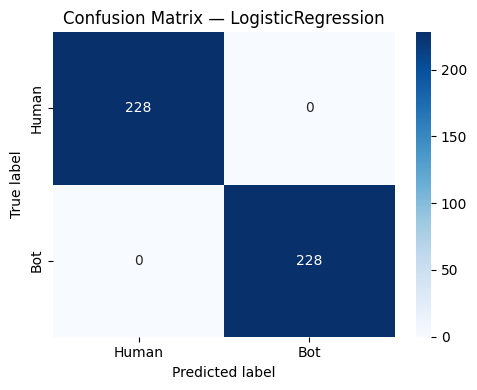

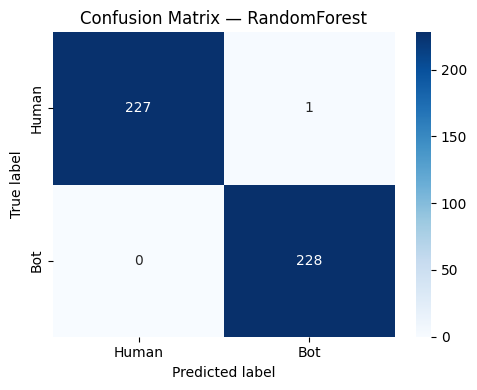

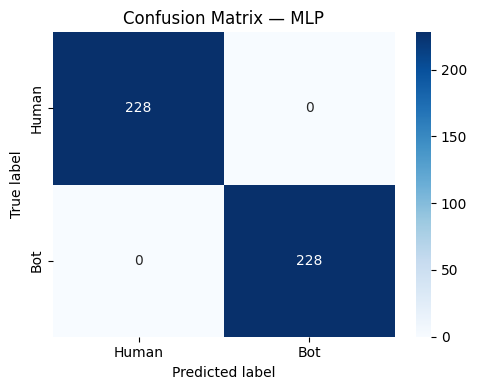

In [15]:
for name in all_models:
    subset = predictions_df[
        predictions_df["model"] == name
        ]

    cm = confusion_matrix(
        subset["y_true"],
        subset["y_pred"],
        labels=[0, 1]
    )

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Human", "Bot"],
        yticklabels=["Human", "Bot"]
    )

    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()

    filename = (
            "confusion_matrix_"
            + name.lower().replace(" ", "_")
            + ".png"
    )

    plt.savefig(OUTPUT_DIR / filename, dpi=150)
    plt.show()
    plt.close()

In [16]:
config = {
    "experiment": "E1 - Fox8-23 Behavioral Representation Learning",
    "random_seed": SEED,
    "device": str(DEVICE),
    "split_file": str(SPLIT_PATH),
    "split_ratio_expected": {
        "train": 0.70,
        "validation": 0.10,
        "test": 0.20
    },
    "text_preprocessing": {
        "max_tweets_per_account": 30,
        "max_characters_per_account": 5000,
        "lowercase": True,
        "tfidf_ngram_range": [1, 2],
        "tfidf_max_features": 10000,
        "tfidf_min_df": 2
    },
    "models": {
        "LogisticRegression": {
            "max_iter": 2000,
            "class_weight": "balanced"
        },
        "RandomForest": {
            "n_estimators": 200,
            "class_weight": "balanced"
        },
        "MLP": {
            "hidden_dim": 256,
            "embedding_dim": 128,
            "epochs_max": 20,
            "early_stopping_patience": 4,
            "batch_size": 64,
            "learning_rate": 0.001
        }
    },
    "excluded_fields": ["dataset"],
    "note": (
        "Input representation is TF-IDF from account tweet text; "
        "source-label confounding may limit generalization."
    )
}

with open(OUTPUT_DIR / "e1_config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

print("All E1 outputs saved in:", OUTPUT_DIR.resolve())

All E1 outputs saved in: /Users/su/Documents/Fox8 baseline bot detection/e1_outputs


In [26]:
import torch

checkpoint = torch.load(
    "e1_outputs/e1_mlp_full_checkpoint.pt",
    map_location="cpu",
    weights_only=True
)

print(type(checkpoint))

if isinstance(checkpoint, dict):
    print("Keys:", checkpoint.keys())
    for key, value in checkpoint.items():
        if isinstance(value, torch.Tensor):
            print(key, value.shape, value.dtype)
        else:
            print(key, type(value))

<class 'dict'>
Keys: dict_keys(['model_state_dict', 'input_dim', 'hidden_dim', 'embedding_dim', 'seed'])
model_state_dict <class 'collections.OrderedDict'>
input_dim <class 'int'>
hidden_dim <class 'int'>
embedding_dim <class 'int'>
seed <class 'int'>
